In [2]:
import pandas as pd

Xtr = pd.read_csv("../data/X_train.csv")
Xte = pd.read_csv("../data/X_test.csv")
y_train = pd.read_csv("../data/y_train.csv").squeeze()
y_test = pd.read_csv("../data/y_test.csv").squeeze()

financial_cols = ["Debtor", "Tuition fees up to date", "Scholarship holder", "financial_pressure"]

attendance_cols = [
    # copy your full list from 05_modelling here
]

In [4]:
financial_cols = ["Debtor", "Tuition fees up to date", "Scholarship holder", "financial_pressure"]

attendance_cols = ["Daytime/evening attendance",
                   "Curricular units 1st sem (enrolled)",
                   "Curricular units 1st sem (evaluations)",
                   "Curricular units 1st sem (approved)",
                   "Curricular units 1st sem (without evaluations)",
                   "pass_rate_1st_sem"]

# Keep only names that exist, and flag any that don't
for name, cols in [("financial", financial_cols), ("attendance", attendance_cols)]:
    missing = [c for c in cols if c not in Xtr.columns]
    print(name, "missing:", missing if missing else "none")

financial_cols = [c for c in financial_cols if c in Xtr.columns]
attendance_cols = [c for c in attendance_cols if c in Xtr.columns]

financial missing: none
attendance missing: none


In [5]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, accuracy_score, f1_score, ConfusionMatrixDisplay
import pandas as pd
import matplotlib.pyplot as plt

feature_sets = {
    "Financial only": financial_cols,
    "Attendance/academic only": attendance_cols,
    "All features": list(Xtr.columns),
}

# max_depth and min_samples_leaf stop the tree overfitting
tree_params = dict(max_depth=5, min_samples_leaf=20,
                   class_weight="balanced", random_state=42)

tree_models, tree_rows = {}, []
for name, cols in feature_sets.items():
    tree = DecisionTreeClassifier(**tree_params).fit(Xtr[cols], y_train)
    pred = tree.predict(Xte[cols])
    tree_models[name] = tree

    print(f"\n===== {name} =====")
    print(classification_report(y_test, pred))

    tree_rows.append({
        "Model": name,
        "Features": len(cols),
        "Train acc": accuracy_score(y_train, tree.predict(Xtr[cols])),
        "Accuracy": accuracy_score(y_test, pred),
        "Macro F1": f1_score(y_test, pred, average="macro"),
    })

tree_results = pd.DataFrame(tree_rows).set_index("Model").round(3)
tree_results


===== Financial only =====
              precision    recall  f1-score   support

     Dropout       0.87      0.33      0.48       284
    Enrolled       0.22      0.79      0.34       159
    Graduate       0.79      0.35      0.49       442

    accuracy                           0.42       885
   macro avg       0.62      0.49      0.43       885
weighted avg       0.71      0.42      0.46       885


===== Attendance/academic only =====
              precision    recall  f1-score   support

     Dropout       0.78      0.57      0.66       284
    Enrolled       0.34      0.56      0.43       159
    Graduate       0.82      0.78      0.80       442

    accuracy                           0.67       885
   macro avg       0.65      0.63      0.63       885
weighted avg       0.72      0.67      0.69       885


===== All features =====
              precision    recall  f1-score   support

     Dropout       0.79      0.62      0.69       284
    Enrolled       0.32      0.58    

,Features,Train acc,Accuracy,Macro F1
Model,,,,
Financial only,4,0.435,0.421,0.433
Attendance/academic only,6,0.669,0.671,0.627
All features,232,0.695,0.659,0.626


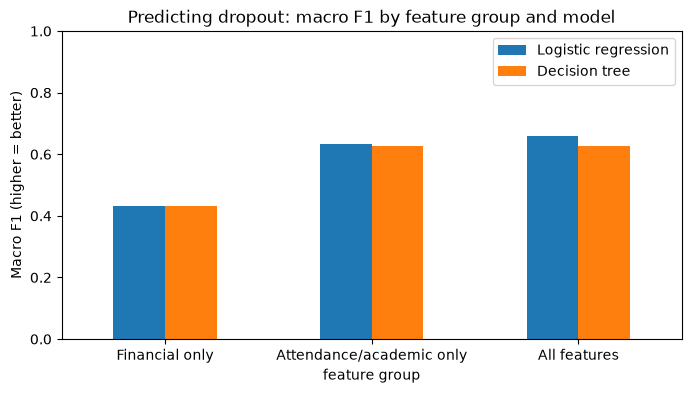

,Logistic regression,Decision tree
Model,,
Financial only,0.432,0.433
Attendance/academic only,0.632,0.627
All features,0.658,0.626


In [12]:
comparison = pd.DataFrame({
    "Logistic regression": [0.432, 0.632, 0.658],
    "Decision tree": tree_results["Macro F1"].values,
}, index=tree_results.index)

comparison.plot(kind="bar", rot=0, figsize=(8, 4),
                title="Predicting dropout: macro F1 by feature group and model")
plt.ylabel("Macro F1 (higher = better)")
plt.xlabel("feature group")
plt.ylim(0, 1)
plt.show()
comparison

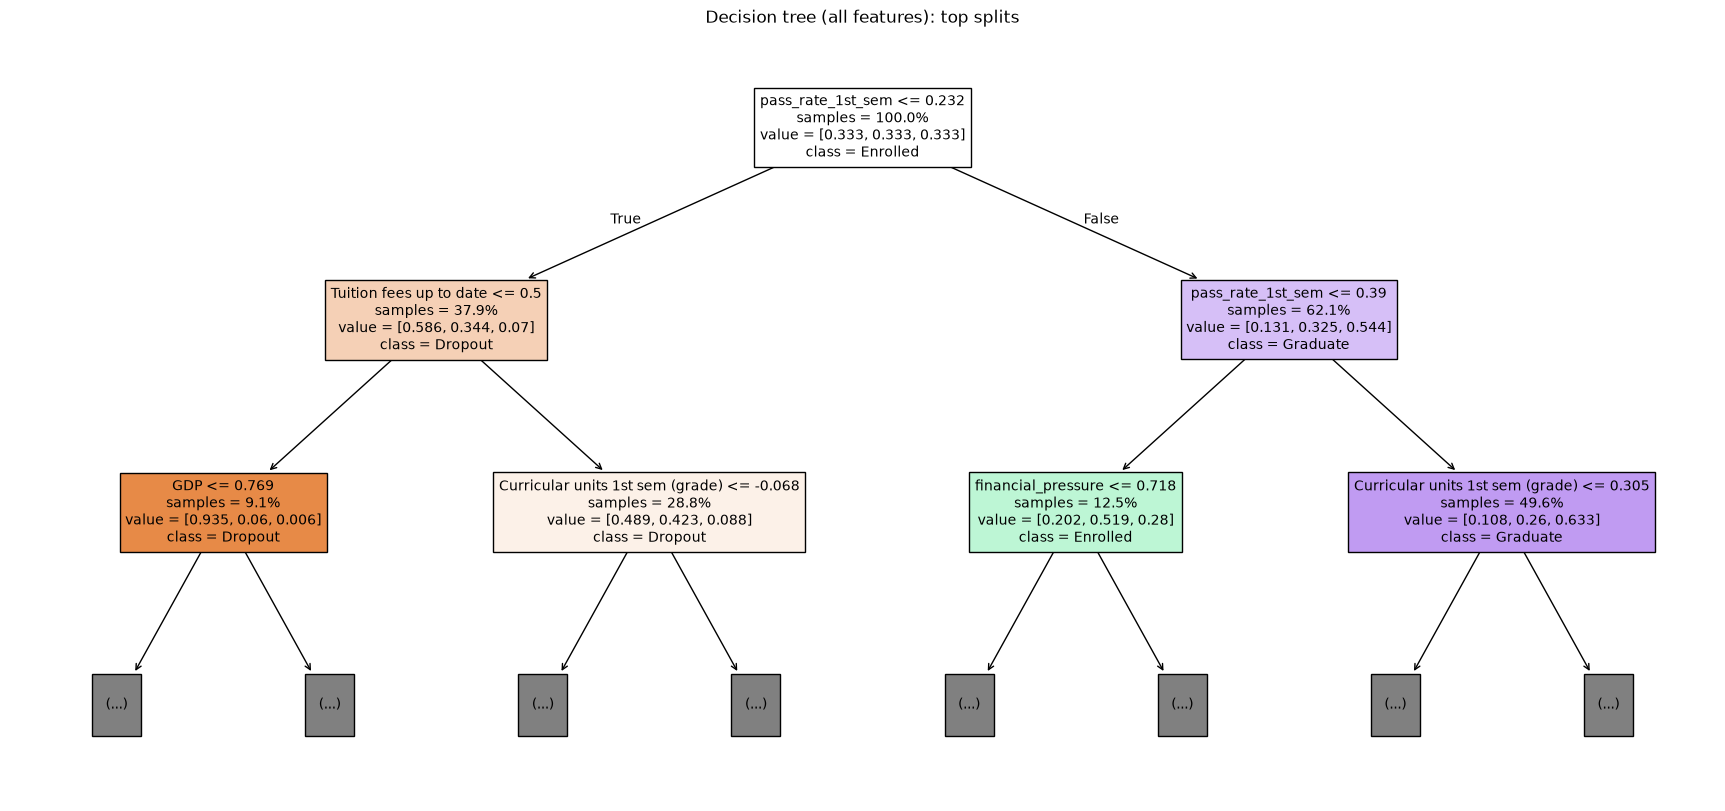

In [8]:
full_tree = tree_models["All features"]

plt.figure(figsize=(22, 10))
plot_tree(full_tree,
          feature_names=Xtr.columns,
          class_names=[str(c) for c in full_tree.classes_],
          filled=True, impurity=False, proportion=True,
          max_depth=2, fontsize=10)   # show only the top 3 levels so it's readable
plt.title("Decision tree (all features): top splits")
plt.show()

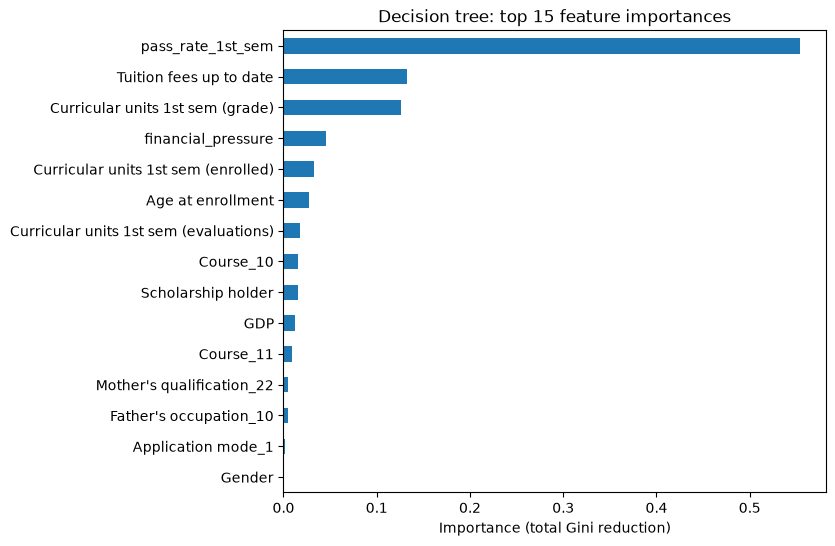

Financial                    0.194
Attendance/academic          0.604
Other (demographics etc.)    0.203
dtype: float64

In [9]:
imp = pd.Series(full_tree.feature_importances_, index=Xtr.columns).sort_values(ascending=False)

imp.head(15).sort_values().plot(kind="barh", figsize=(7, 6),
                                title="Decision tree: top 15 feature importances")
plt.xlabel("Importance (total Gini reduction)")
plt.show()

group_imp = pd.Series({
    "Financial": imp[financial_cols].sum(),
    "Attendance/academic": imp[attendance_cols].sum(),
    "Other (demographics etc.)": imp.drop(financial_cols + attendance_cols).sum(),
}).round(3)
group_imp

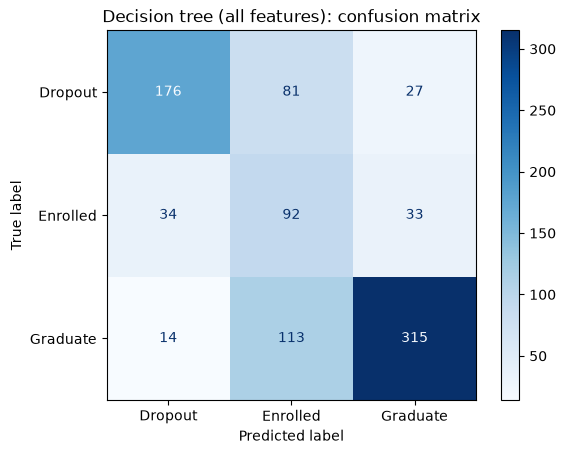

In [10]:
ConfusionMatrixDisplay.from_estimator(full_tree, Xte, y_test, cmap="Blues")
plt.title("Decision tree (all features): confusion matrix")
plt.show()

In [11]:
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(
    DecisionTreeClassifier(class_weight="balanced", random_state=42),
    {"max_depth": [3, 4, 5, 6, 8, 10, None],
     "min_samples_leaf": [1, 5, 10, 20, 50]},
    cv=5, scoring="f1_macro",
)
grid.fit(Xtr, y_train)   # tuned on training data only
print(grid.best_params_, round(grid.best_score_, 3))

{'max_depth': 6, 'min_samples_leaf': 10} 0.638


model evlauation: 5 fold cross validation 

In [13]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Logistic regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, class_weight="balanced")),
    ]),
    "Decision tree": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42),
}

groups = {
    "Financial only": financial_cols,
    "Attendance/academic only": attendance_cols,
    "All features": list(Xtr.columns),
}

rows = []
for model_name, model in models.items():
    for group_name, cols in groups.items():
        scores = cross_validate(model, Xtr[cols], y_train, cv=cv, scoring="f1_macro")
        rows.append([model_name, group_name,
                     scores["test_score"].mean(), scores["test_score"].std()])

cv_results = pd.DataFrame(rows, columns=["Model", "Features", "CV Macro F1 mean", "CV Macro F1 SD"]).round(3)
cv_results

,Model,Features,CV Macro F1 mean,CV Macro F1 SD
0,Logistic regression,Financial only,0.441,0.012
1,Logistic regression,Attendance/academic only,0.611,0.012
2,Logistic regression,All features,0.668,0.021
3,Decision tree,Financial only,0.441,0.010
4,Decision tree,Attendance/academic only,0.609,0.006
5,Decision tree,All features,0.634,0.024
